# Ejercicio practico - Big Data y MLOps (PY4)

Este notebook es un ejercicio de practica que reune lo que trabajamos en el modulo: crear una `SparkSession`, cargar y explorar datos, entender particiones, limpiar y transformar un dataset, calcular agregaciones, y leer el plan de ejecucion de Spark.


Al final hay una seccion opcional (pero recomendada) donde vas a persistir tu resultado en una base de datos MySQL usando Docker.

## Preparacion del dataset

Esta celda genera el mismo dataset simulado de transacciones que usamos en las sesiones anteriores. No es parte del ejercicio, solo asegura que tengas datos para trabajar.

In [ ]:
!pip install numpy pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 754.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 14.1 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [ ]:


import numpy as np
import pandas as pd
import os

np.random.seed(7)

n_filas = 60000

categorias_base = ["Electronica", "Ropa", "Alimentos", "Hogar", "Deportes", "Tecnologia"]
canales = ["App", "Web", "Tienda Fisica"]

id_transaccion = np.arange(1, n_filas + 1)
duplicados = np.random.choice(id_transaccion, size=200, replace=False)
id_transaccion = np.concatenate([id_transaccion, duplicados])
np.random.shuffle(id_transaccion)

n_total = len(id_transaccion)

cliente_id = np.random.randint(1000, 5000, size=n_total)

categoria_base_muestreada = np.random.choice(categorias_base, size=n_total)

def desordenar_texto(texto):
    opcion = np.random.random()
    if opcion < 0.3:
        return texto.upper()
    elif opcion < 0.6:
        return texto.lower()
    return texto

categoria = np.array([desordenar_texto(c) for c in categoria_base_muestreada], dtype=object)

monto = np.random.lognormal(mean=4.5, sigma=1.0, size=n_total).round(2).astype(object)

for i in np.random.choice(n_total, size=150, replace=False):
    monto[i] = -monto[i]
for i in np.random.choice(n_total, size=400, replace=False):
    monto[i] = None
for i in np.random.choice(n_total, size=300, replace=False):
    categoria[i] = None

canal = np.random.choice(canales, size=n_total, p=[0.5, 0.35, 0.15])

fecha_inicio = pd.Timestamp("2024-01-01")
offsets_minutos = np.random.randint(0, 60 * 24 * 60, size=n_total)
fecha_hora = fecha_inicio + pd.to_timedelta(offsets_minutos, unit="m")

df_transacciones = pd.DataFrame({
    "id_transaccion": id_transaccion,
    "cliente_id": cliente_id,
    "categoria": categoria,
    "monto": monto,
    "canal": canal,
    "fecha_hora": fecha_hora,
})

os.makedirs("data", exist_ok=True)
ruta_csv = "data/transacciones_masivas.csv"
df_transacciones.to_csv(ruta_csv, index=False)

print(f"Dataset generado con {len(df_transacciones)} filas.")


Dataset generado con 60200 filas.


## Ejercicio 1: Crear la SparkSession

Crea una `SparkSession` con un `appName` descriptivo, por ejemplo `"PY4_Ejercicio_BigData"`.

In [ ]:

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("PY4_Ejercicio_BigData")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/14 02:54:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Ejercicio 2: Cargar el CSV con un schema explicito

Define un `schema` manual con `StructType` para las columnas del dataset (`id_transaccion`, `cliente_id`, `categoria`, `monto`, `canal`, `fecha_hora`), y usa ese schema para leer el archivo `data/transacciones_masivas.csv`.

In [ ]:
from pyspark.sql.types import (
    StructType, StructField, IntegerType, StringType, DoubleType, TimestampType
)

schema = StructType([
    StructField("id_transaccion", IntegerType(), True),
    StructField("cliente_id", IntegerType(), True),
    StructField("categoria", StringType(), True),
    StructField("monto", DoubleType(), True),
    StructField("canal", StringType(), True),
    StructField("fecha_hora", TimestampType(), True),
])

df_spark = spark.read.csv(
    "data/transacciones_masivas.csv",
    header=True,
    schema=schema
)

df_spark.printSchema()

root
 |-- id_transaccion: integer (nullable = true)
 |-- cliente_id: integer (nullable = true)
 |-- categoria: string (nullable = true)
 |-- monto: double (nullable = true)
 |-- canal: string (nullable = true)
 |-- fecha_hora: timestamp (nullable = true)



## Ejercicio 3: Exploracion basica

Muestra el schema del DataFrame, las primeras 5 filas, y el numero total de filas.

In [ ]:
df_spark.printSchema()
df_spark.show(5)
print("Total de filas:", df_spark.count())

root
 |-- id_transaccion: integer (nullable = true)
 |-- cliente_id: integer (nullable = true)
 |-- categoria: string (nullable = true)
 |-- monto: double (nullable = true)
 |-- canal: string (nullable = true)
 |-- fecha_hora: timestamp (nullable = true)

+--------------+----------+----------+------+-----+-------------------+
|id_transaccion|cliente_id| categoria| monto|canal|         fecha_hora|
+--------------+----------+----------+------+-----+-------------------+
|         24481|      2923|  DEPORTES| 59.84|  Web|2024-01-24 18:22:00|
|          5981|      2841|tecnologia|343.12|  App|2024-02-03 14:37:00|
|         41489|      3625|  Deportes|246.84|  App|2024-01-26 07:19:00|
|         32220|      2032|Tecnologia| 55.67|  Web|2024-02-13 23:45:00|
|         12526|      3976|  Deportes|107.52|  Web|2024-02-09 17:11:00|
+--------------+----------+----------+------+-----+-------------------+
only showing top 5 rows
Total de filas: 60200


## Ejercicio 4: Particiones

Revisa cuantas particiones tiene `df_spark`. Despues, usa `repartition()` para llevarlo a 4 particiones y confirma el cambio.

In [ ]:
print("Particiones actuales:", df_spark.rdd.getNumPartitions())

df_spark = df_spark.repartition(4)

print("Particiones despues de repartition(4):", df_spark.rdd.getNumPartitions())

Particiones actuales: 1
Particiones despues de repartition(4): 4


## Ejercicio 5: Limpieza

A partir de `df_spark`, crea `df_limpio` aplicando lo siguiente:

- Elimina duplicados por `id_transaccion`.
- Elimina filas con `monto` o `categoria` nulos.
- Filtra los montos negativos o iguales a cero.
- Estandariza el texto de `categoria` (primera letra en mayuscula, el resto en minuscula).

In [ ]:
from pyspark.sql import functions as F

df_limpio = (
    df_spark
    .dropDuplicates(["id_transaccion"])
    .dropna(subset=["monto", "categoria"])
    .filter(F.col("monto") > 0)
    .withColumn(
        "categoria",
        F.initcap(F.trim(F.col("categoria")))
    )
)

print("Filas antes de limpiar:", df_spark.count())
print("Filas despues de limpiar:", df_limpio.count())
df_limpio.select("categoria").distinct().show()

Filas antes de limpiar: 60200
Filas despues de limpiar: 59158


+-----------+
|  categoria|
+-----------+
|   Deportes|
|       Ropa|
|      Hogar|
| Tecnologia|
|  Alimentos|
|Electronica|
+-----------+



## Ejercicio 6: Transformacion

A partir de `df_limpio`, crea `df_procesado` agregando dos columnas nuevas:

- `total_con_impuestos`: el `monto` con un 15% de impuesto aplicado.
- `hora`: la hora del dia extraida de `fecha_hora`.

In [ ]:
IMPUESTO = 0.15

df_procesado = (
    df_limpio
    .withColumn("total_con_impuestos", F.round(F.col("monto") * (1 + IMPUESTO), 2))
    .withColumn("hora", F.hour(F.col("fecha_hora")))
)

df_procesado.select("monto", "total_con_impuestos", "fecha_hora", "hora").show(5)

+------+-------------------+-------------------+----+
| monto|total_con_impuestos|         fecha_hora|hora|
+------+-------------------+-------------------+----+
|404.35|              465.0|2024-01-31 10:54:00|  10|
| 95.37|             109.68|2024-01-03 06:28:00|   6|
|183.43|             210.94|2024-01-16 10:36:00|  10|
| 19.84|              22.82|2024-01-15 08:37:00|   8|
|265.95|             305.84|2024-02-27 10:58:00|  10|
+------+-------------------+-------------------+----+
only showing top 5 rows


## Ejercicio 7: Agregacion

Agrupa `df_procesado` por `categoria` y calcula el promedio de `total_con_impuestos` y la cantidad de transacciones por categoria. Ordena el resultado de mayor a menor promedio. Guarda el resultado en `resumen_por_categoria`.

In [ ]:
resumen_por_categoria = (
    df_procesado
    .groupBy("categoria")
    .agg(
        F.round(F.avg("total_con_impuestos"), 2).alias("promedio_total_con_impuestos"),
        F.count("*").alias("cantidad_transacciones")
    )
    .orderBy(F.desc("promedio_total_con_impuestos"))
)

resumen_por_categoria.show()

+-----------+----------------------------+----------------------+
|  categoria|promedio_total_con_impuestos|cantidad_transacciones|
+-----------+----------------------------+----------------------+
|  Alimentos|                       173.9|                  9789|
|Electronica|                      173.63|                  9906|
| Tecnologia|                      172.89|                  9758|
|       Ropa|                      171.14|                  9807|
|   Deportes|                      171.13|                 10020|
|      Hogar|                       169.8|                  9878|
+-----------+----------------------------+----------------------+



## Ejercicio 8: Plan de ejecucion

Usa `.explain()` sobre un `filter` simple hecho directamente sobre `df_spark` (por ejemplo `monto > 1000`), y tambien sobre `resumen_por_categoria`. Compara los dos planes: identifica cual de los dos incluye un paso `Exchange`, y a que tipo de transformacion corresponde (narrow o wide).

In [ ]:
print("=== Plan: filter simple sobre df_spark (narrow) ===")
df_spark.filter(F.col("monto") > 1000).explain()

print("\n=== Plan: resumen_por_categoria (wide - tiene groupBy) ===")
resumen_por_categoria.explain()

=== Plan: filter simple sobre df_spark (narrow) ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Exchange RoundRobinPartitioning(4), REPARTITION_BY_NUM, [plan_id=905]
   +- Filter (isnotnull(monto#3) AND (monto#3 > 1000.0))
      +- FileScan csv [id_transaccion#0,cliente_id#1,categoria#2,monto#3,canal#4,fecha_hora#5] Batched: false, DataFilters: [isnotnull(monto#3), (monto#3 > 1000.0)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/workspace/data/transacciones_masivas.csv], PartitionFilters: [], PushedFilters: [IsNotNull(monto), GreaterThan(monto,1000.0)], ReadSchema: struct<id_transaccion:int,cliente_id:int,categoria:string,monto:double,canal:string,fecha_hora:ti...



=== Plan: resumen_por_categoria (wide - tiene groupBy) ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [promedio_total_con_impuestos#220 DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(promedio_total_con_impuestos#220 DESC NULLS LAST, 8), ENSURE_REQUIREMENTS, [plan_

## Conclusión Ejercicio 8

El plan de `df_spark.filter(monto > 1000)` muestra un `Exchange RoundRobinPartitioning`,
pero no proviene del `filter` en sí — un filtro es una transformación **narrow**
(cada partición se procesa de forma independiente, sin mover datos entre ellas).
Ese `Exchange` viene arrastrado del `repartition(4)` aplicado antes en el Ejercicio 4.

En cambio, el plan de `resumen_por_categoria` sí contiene varios `Exchange` que
corresponden genuinamente a transformaciones **wide**:

- `Exchange hashpartitioning(id_transaccion, 8)` → generado por `dropDuplicates(["id_transaccion"])`
- `Exchange hashpartitioning(categoria, 8)` → generado por `groupBy("categoria")`
- `Exchange rangepartitioning(...)` → generado por `orderBy()`

Estas operaciones requieren *shuffle*: mover datos entre particiones para agrupar
filas con la misma clave o para ordenar el resultado global. Por eso el `groupBy`
+ `orderBy` genera un plan mucho más costoso que un simple `filter`.

## Seccion opcional (pero recomendada): persistencia en MySQL

Hasta aqui trabajaste todo el pipeline dentro de Spark. Esta seccion es opcional, pero se recomienda completarla: vas a persistir tu resultado en una base de datos MySQL real, usando el entorno Docker que se te entrego por separado.

Esta seccion no tiene celdas de codigo propias. En su lugar, sigue estos pasos:

1. Sigue el README (`Configuracion del entorno local con Docker y Google Colab`) entregado por separado para instalar Docker Desktop y levantar el entorno del proyecto `py4-docker`.  

2. Una vez que el entorno este corriendo (`docker compose up -d`), conecta Google Colab a ese local runtime.  

3. Abre el notebook `persistencia_MySQL.ipynb` (usando el entorno Docker) y ejecuta sus celdas en orden. Ese notebook contiene el pipeline completo (no necesita escribir codigo), incluyendo la configuracion del driver JDBC y la escritura del resultado en MySQL.  

4. Cuando termines, verifica la tabla directamente desde la terminal, dentro del container de MySQL:

```bash
docker compose exec mysql mysql -u root -p bigdata_py4
```

```sql
SELECT * FROM resumen_ventas_categoria;
```

### Evidencia a entregar

Toma una captura de pantalla de tu terminal mostrando el resultado de ese `SELECT`, con las filas de la tabla visibles. Esa captura es la evidencia de que tu resultado quedo persistido en MySQL.

Saving Captura de pantalla (178).png to Captura de pantalla (178).png


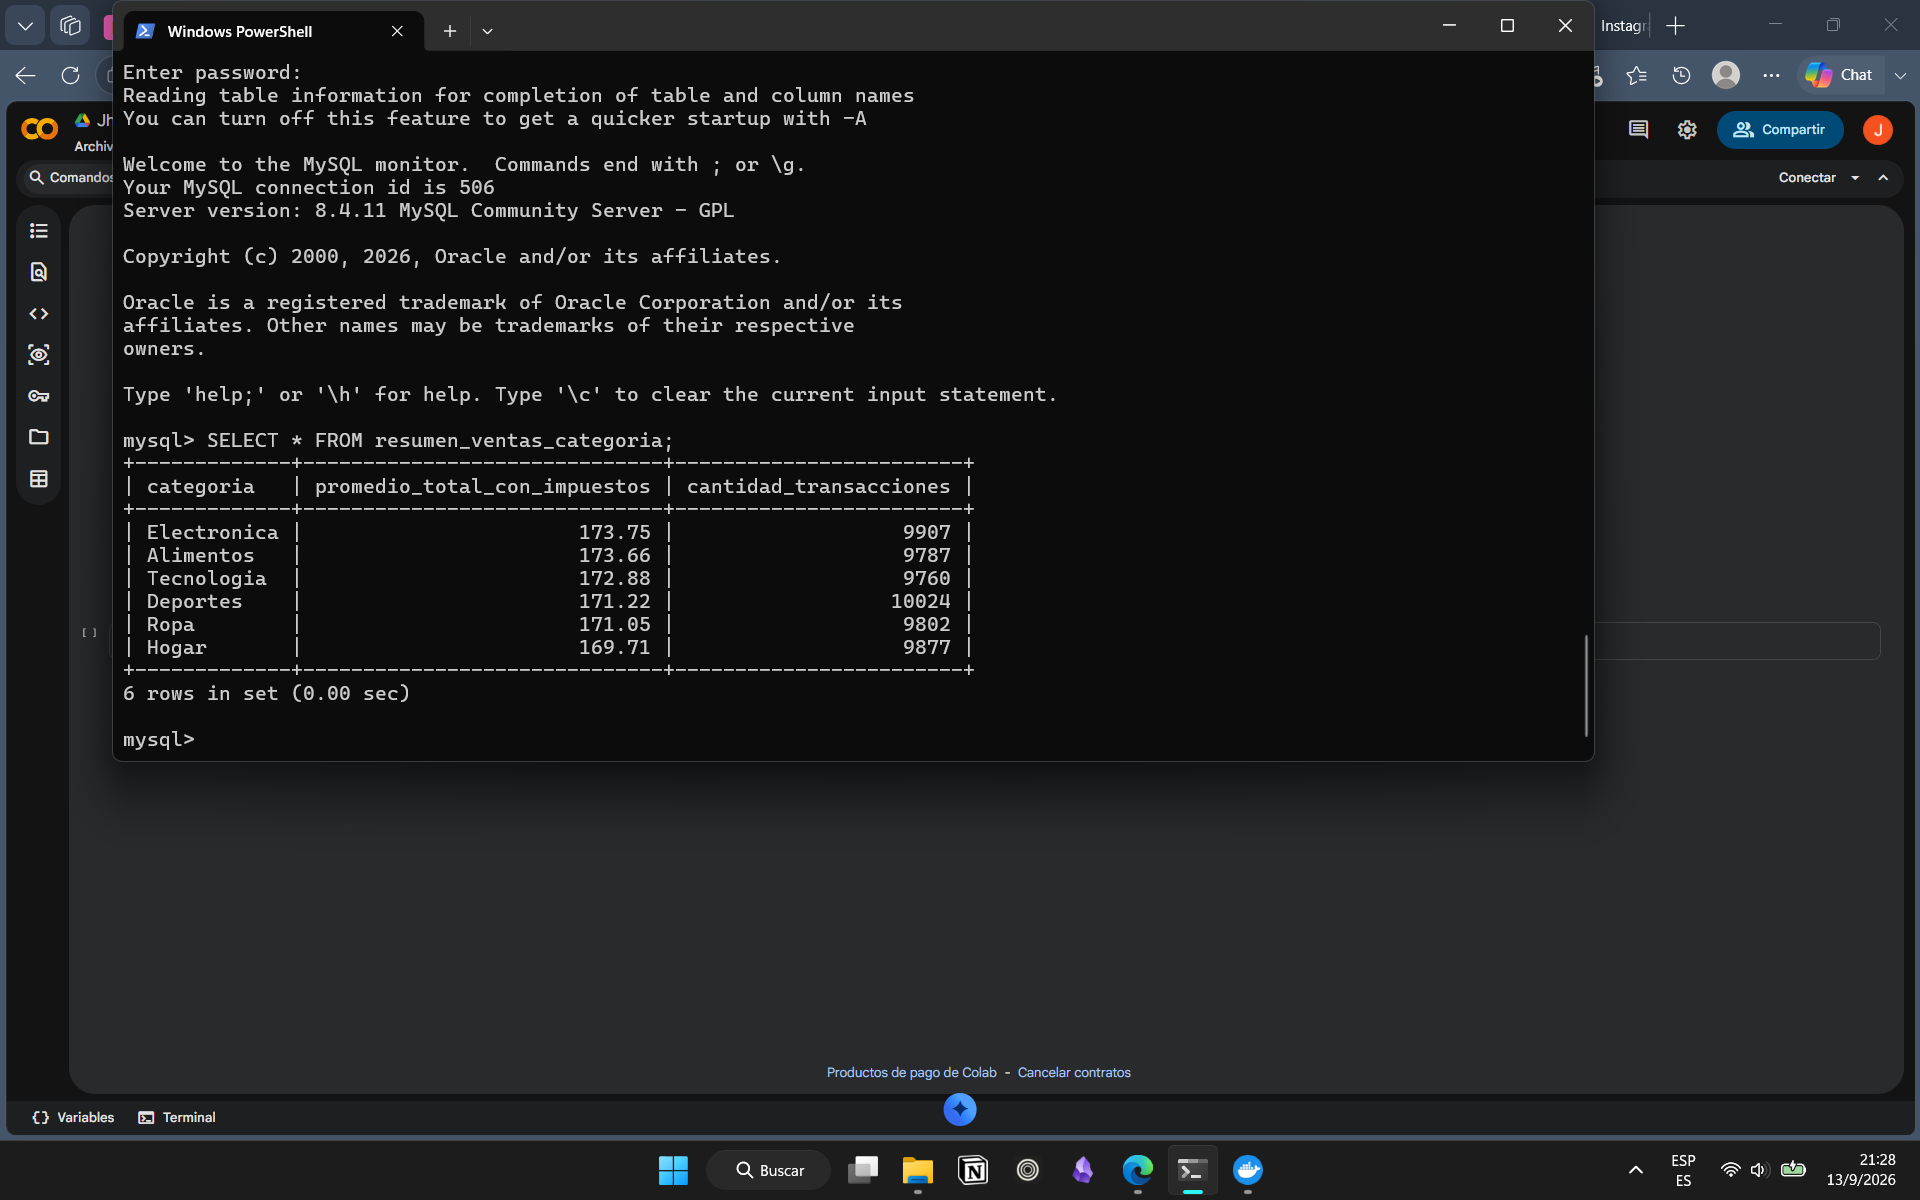

In [1]:
from google.colab import files
uploaded = files.upload()  # se abre un selector, elegí tu captura (.png o .jpg)

from IPython.display import Image, display
nombre_archivo = list(uploaded.keys())[0]
display(Image(filename=nombre_archivo))